# Posterior analysis of the data

Classical exploratory analysis studies the data before any model, with summaries and the judgement of
an analyst who decides which values look wrong. Posterior analysis reads each datum against what the
other data say about it. Spatialize builds, for every datum, the law the rest of the data and the
partitions give it, without the datum and without a variogram, and reads how far into that law the datum
falls. The evidence comes from the data themselves. This tutorial audits a set of data with planted
problems of every kind the analysis reads, measures how far its flags can be trusted, adds a second
variable measured on the same samples, and ends on a real data set.

## Learning goals

- How `posterior_audit` builds the law of each datum from the other data, and why its calibration is read
  before its flags.
- How the flags control the false discovery rate, how far they keep that promise, and how `null_flags`
  measures it on the data at hand.
- How the neighbours of a surprising datum tell a lone error from a part of the domain the other data do
  not represent.
- How much evidence stands behind each law, how much of the domain each datum represents, and which data
  share a location.
- How a second variable measured on the same samples finds errors the neighbours alone do not show.
- How `recommend` turns the readings into a list of actions, which samples to measure again and where to
  sample more.

*Which data do the other data not support?*

## The idea

Cross-validation predicts each datum $z_i$ from the other data, one member per partition, which gives
its law $\hat F_{-i}$ without the datum. The position of the datum in that law, $u_i = \tilde F_i(z_i)$,
and its two-sided tail probability, $p_i = 2\min(u_i, 1 - u_i)$, say how surprising it is. When the law
is right, $u_i$ is uniform and $p_i$ is a p-value. With hundreds of data, a few fall in the tails by
chance, so Spatialize flags them with the Benjamini–Hochberg procedure, which bounds the expected share
of clean data among the flagged ones by a rate $q$.

That promise rests on laws whose probabilities are right. The members of an ensemble average the data
of a cell, so they spread less than the data do, which makes their laws too narrow and too light in
their tails. Spatialize widens each law to the spread of the neighbouring data, spreads all of them by one
factor fitted to the data and carries them past their sample with Student-t kernels. The data tell
whether this succeeds, so the calibration comes first. The log score of a datum,
$-\log \tilde f_i(z_i)$, has the entropy of the law as its expectation when the datum follows its law,
which gives a second check that reads the whole law.

A flag is evidence, not a verdict. A value its neighbours do not support may be a gross error or a part
of the domain the other data do not represent, and only the provenance of the datum decides. The
analysis gives the evidence and an order, from the most to the least surprising datum
([the theory Spatialize rests on](https://spatialize.readthedocs.io/en/latest/theory/posterior.html)).

## Step by step

### A field with planted problems

400 samples on the unit square measure a smooth field, plus what each sample holds of its own, plus a
measurement error. A hundred of them were taken where the field is high, as happens when sampling
follows interest. Each sample also has a second variable, measured on the same sample, which shares
what the sample holds. Into the first variable we plant the problems an analysis should find:

- a decimal error, a value multiplied by 10;
- a value shifted by 1.2, inside the range of its neighbours;
- two values swapped between distant samples;
- a raised patch of about ten samples, a sub-population present in both variables;
- a duplicated sample at the same location, its copy carrying a value 2.5 higher.

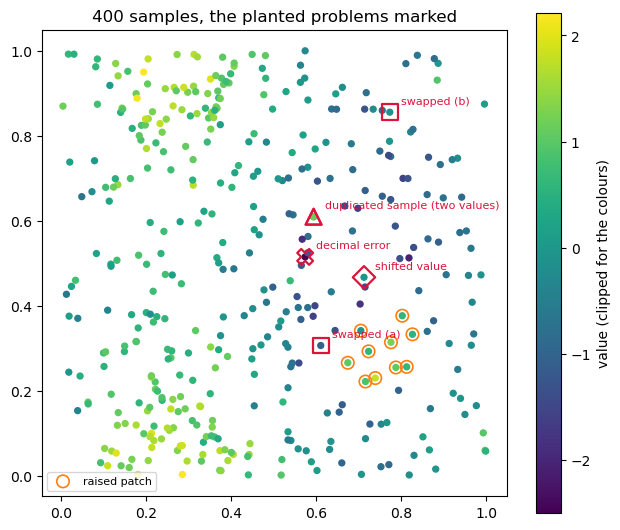

401 data, 10 in the patch, the decimal error reads -10.94


In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.gs.esi import esi_hparams_search
from spatialize.gs.spa import posterior_audit
from spatialize.logging import singleton_null_callback as quiet

spatialize.session.set(empty_cells="coarsen", progress=False)
warnings.filterwarnings("ignore", category=UserWarning)

field = lambda p: np.sin(2 * np.pi * p[:, 0]) + 0.5 * np.cos(2 * np.pi * p[:, 1])


def draw_samples(seed, n_uniform=300, n_cluster=100):
    # samples uniform on the square plus a cluster where the field is high, two variables per sample
    rng = np.random.default_rng(seed)
    pool = rng.random((20000, 2))
    points = np.vstack([rng.random((n_uniform, 2)), pool[field(pool) > 1.0][:n_cluster]])
    own = rng.normal(0, 0.4, len(points))                  # what each sample holds of its own
    u = field(points) + own + rng.normal(0, 0.1, len(points))
    v = field(points) + own + rng.normal(0, 0.1, len(points))
    return points, u, v


points, clean, v = draw_samples(19)
values = clean.copy()
patch = np.all(np.abs(points - [0.75, 0.3]) < 0.08, axis=1)
values[patch] += 2.0
v[patch] += 2.0
away = np.flatnonzero(~patch & (np.arange(len(points)) < 300))
decimal, shifted, swap_a, swap_b, original = away[[3, 40, 80, 160, 200]]
values[decimal] *= 10
values[shifted] += 1.2
values[swap_a], values[swap_b] = values[swap_b], values[swap_a]
points = np.vstack([points, points[original]])
values, v = np.append(values, values[original] + 2.5), np.append(v, v[original])
patch = np.append(patch, False)
copy = len(values) - 1
planted = {"decimal error": decimal, "shifted value": shifted, "swapped (a)": swap_a, "swapped (b)": swap_b,
           "duplicate, original": original, "duplicate, copy": copy}

fig, ax = plt.subplots(figsize=(7.5, 6.5))
sc = ax.scatter(points[:, 0], points[:, 1], c=np.clip(values, -2.5, 3.5), cmap="viridis", s=18)
ax.scatter(*points[patch].T, s=80, facecolors="none", edgecolors="tab:orange", lw=1.2, label="raised patch")
markers = dict(zip(planted, ["X", "D", "s", "s", "^", "^"]))
labels = dict(planted)
labels.pop("duplicate, copy")
labels["duplicated sample (two values)"] = labels.pop("duplicate, original")
for name, i in planted.items():
    ax.scatter(*points[i], s=130, marker=markers[name], facecolors="none", edgecolors="crimson", lw=1.6)
for name, i in labels.items():
    ax.annotate(name, points[i], xytext=(8, 6), textcoords="offset points", fontsize=8, color="crimson")
fig.colorbar(sc, ax=ax, label="value (clipped for the colours)")
ax.set_title("400 samples, the planted problems marked")
ax.legend(loc="lower left", fontsize=8)
ax.set_aspect("equal")
plt.show()
print(f"{len(values)} data, {patch.sum()} in the patch, the decimal error reads {values[decimal]:.2f}")

### Settings chosen by cross-validation

The audit uses the ensemble a cross-validated search chooses for these data, IDW on Mondrian partitions,
with its granularity and exponent picked among a few candidates. The search runs with 50 partitions,
the audit with 300.

In [2]:
search = esi_hparams_search(points, values, points, local_interpolator="idw", griddata=False, k=10,
                            exponent=[1.0, 2.0, 4.0], alpha=(0.7, 0.8, 0.85, 0.9), n_partitions=[50],
                            seed=19, callback=quiet)
best = search.best_result()
recipe = f"Mondrian, IDW (exponent {best['exponent']:g}), alpha {best['alpha']:g}"
print(recipe)

audit = posterior_audit(points, values, local_interpolator="idw", n_partitions=300, seed=19,
                        best_params_found=best, callback=quiet)

Mondrian, IDW (exponent 1), alpha 0.9


### Calibration comes first

A datum lies inside the central interval of probability $\alpha$ of its law with probability $\alpha$
when the law is right. The coverage compares the share of data inside with $\alpha$. The
information check compares the mean excess surprise, the log score minus the entropy, with 0. We read
both for the laws as the members give them, and after the corrections Spatialize applies by default.

,inside 0.5,inside 0.8,inside 0.9,inside 0.95,inside 0.99,tails,centre,information z,flags
members as they are,0.261845,0.501247,0.59601,0.660848,0.793017,too narrow,too narrow,258982643314.009277,83
default corrections,0.568579,0.832918,0.922693,0.9601,0.98005,calibrated,calibrated,-0.248509,1


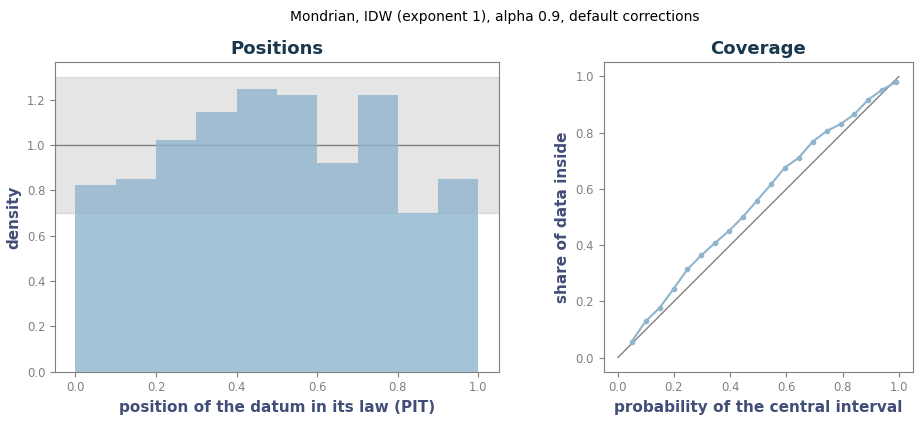

In [3]:
uncorrected = posterior_audit(points, values, local_interpolator="idw", n_partitions=300, seed=19,
                              best_params_found=best, callback=quiet, widening=False, calibrate=False,
                              tails="normal")
rows = {}
for name, a in (("members as they are", uncorrected), ("default corrections", audit)):
    c = a.calibration(information=True)
    row = dict(zip([f"inside {x:g}" for x in c["coverage"].alpha], c["coverage"].observed))
    row.update({"tails": c["verdict"], "centre": c["centre"], "information z": c["information"]["z"],
                "flags": int(a.flags().sum())})
    rows[name] = row
display(pd.DataFrame(rows).T.round(3))

fig = audit.plot_calibration(figsize=(10, 4))
fig.suptitle(f"{recipe}, default corrections", fontsize=10, y=1.04)
plt.show()

Read as they are, the members put two data in five outside their central 90 % interval and flag 83
data, nearly all of them clean, with a warning. The information check runs into the hundreds of
billions, the Gaussian tails of the uncorrected laws making the decimal error almost impossible. After the corrections the coverage
follows $\alpha$ within its errors, the information check lies near 0, the tails being called
calibrated. Only now do the flags mean what they say.

### The surprise of each datum

`table()` gives every reading of every datum. Sorted by the tail probability, the planted problems
come first.

,value,pit,tail_p,flag,surprisal,excess,shift,planted
3,-10.9437,0.0000,0.0000,True,14.0131,13.2915,0.2014,decimal error
209,-1.3406,0.0007,0.0013,False,6.5686,5.6422,-0.0257,"duplicate, original"
352,1.9569,0.9993,0.0014,False,5.6788,5.6057,0.1268,
400,1.1594,0.9992,0.0015,False,6.7842,5.6766,-0.2754,"duplicate, copy"
260,1.9553,0.9986,0.0028,False,4.5328,4.6029,0.1974,
239,1.3441,0.9973,0.0054,False,3.4730,3.7696,-0.1036,
253,-0.1625,0.0027,0.0055,False,3.6442,3.8480,0.0860,
68,1.7009,0.9952,0.0095,False,3.3827,2.8351,0.0493,


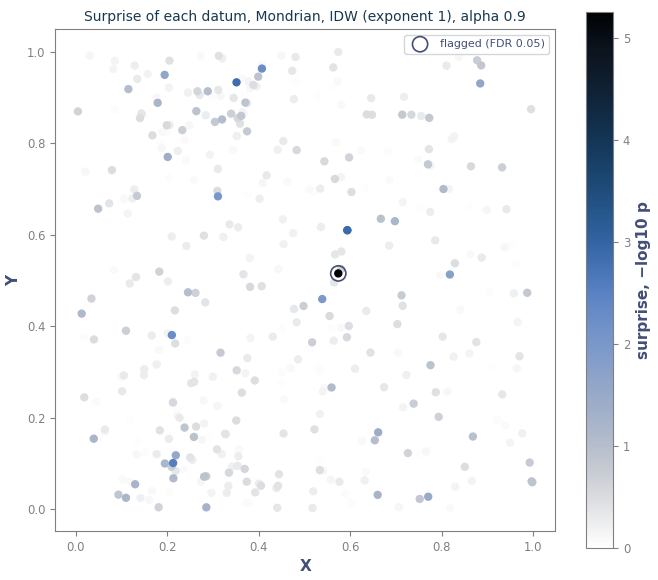

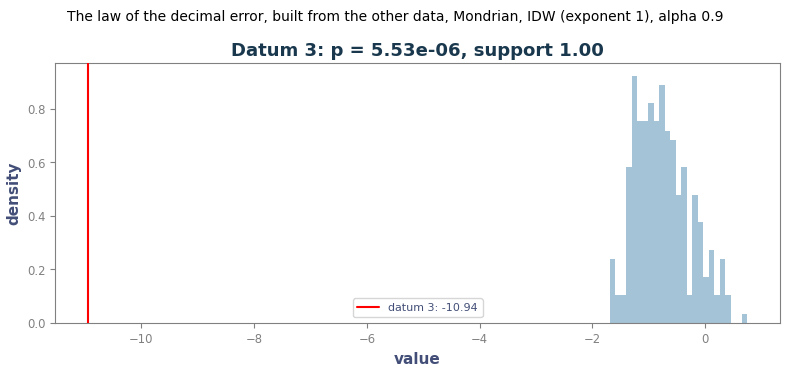

In [4]:
table = audit.table()
names = {i: name for name, i in planted.items()}
names.update({i: "patch" for i in np.flatnonzero(patch)})
table["planted"] = [names.get(i, "") for i in range(len(table))]
display(table.sort_values("tail_p").head(8)[["value", "pit", "tail_p", "flag", "surprisal", "excess", "shift",
                                             "planted"]].round(4))

fig = audit.plot_map(figsize=(7, 6))
fig.axes[0].set_title(f"Surprise of each datum, {recipe}", fontsize=10)
plt.show()

fig = audit.plot_datum(int(decimal), figsize=(8, 3.5))
fig.suptitle(f"The law of the decimal error, built from the other data, {recipe}", fontsize=10, y=1.05)
plt.show()

The decimal error is the only flag, its tail probability far below every other. The duplicated
sample and its copy come next among the most surprising, both deep in the tails, their p-values near
0.001, yet not flagged, since each sees the other as a neighbour. The shifted value and the swapped ones hide among their neighbours,
the share of each sample of its own being large beside a shift of 1.2.

### An error or a part of the domain

A surprising datum may be an error or a part of the domain the other data do not represent. Its
neighbours tell the two apart. An error takes part in the laws of its neighbours and pulls them towards
it, so the neighbours fall on the other side of their laws. Data of an unrepresented part are surprised
together, on the same side. The `shift` of a datum, the mean signed position $2u_j - 1$ of its eight
nearest neighbours, reads this.

In [5]:
shift = audit.shift()
side = np.sign(audit.pit() - 0.5)
summary = pd.DataFrame({
    "own side (+ above its law)": [side[decimal], np.mean(side[patch]), np.mean(side[~patch])],
    "shift of its neighbours": [shift[decimal], np.mean(shift[patch]), np.mean(shift[~patch])]},
    index=["decimal error", "patch (mean)", "other data (mean)"])
display(summary.round(3))

,own side (+ above its law),shift of its neighbours
decimal error,-1.000,0.201
patch (mean),1.000,0.139
other data (mean),-0.043,-0.000


The decimal error lies far below its law, while its neighbours sit above theirs, their laws pulled
down by it, the mark of a lone error. The data of the patch sit above their laws together with their
neighbours, the mark of a part of the domain the rest of the data do not represent. The other data
show no shift.

### The evidence behind each law

A law may rest on little evidence, for a datum alone in its cells or one among neighbours that
disagree. The information gain, the entropy of the distribution of all the data minus that of the law,
says how much the other data tell about each datum. It does not depend on the units. It is near 0
where a law is as wide as the data themselves. Under `empty_cells="coarsen"` every datum has a law in
every partition, so the support is 1 everywhere, leaving the gain to carry the reading.

information gain, nats: median 0.59, 10 % quantile 0.14, 90 % quantile 1.12


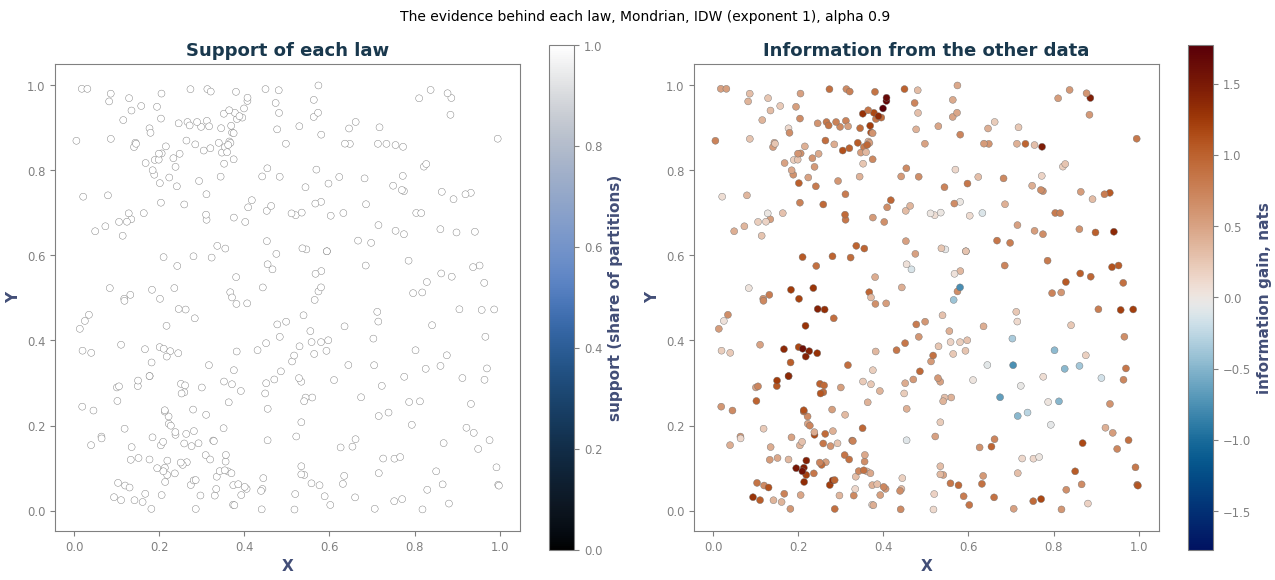

In [6]:
evidence = audit.evidence()
print(f"information gain, nats: median {evidence.gain.median():.2f}, "
      f"10 % quantile {evidence.gain.quantile(0.1):.2f}, 90 % quantile {evidence.gain.quantile(0.9):.2f}")
fig = audit.plot_evidence(figsize=(13, 5.5))
fig.suptitle(f"The evidence behind each law, {recipe}", fontsize=10, y=1.03)
plt.show()

The gain is largest where neighbours are close, inside the cluster of samples, with 0.73 nats against
0.56 elsewhere. It falls where the field changes fastest, the neighbours of a datum disagreeing there.

### The share of the domain behind each datum

The hundred samples taken where the field is high lean the plain summaries towards high values. Each
partition shares the domain among the data, so the partitions give each datum a declustering weight,
the share of the domain it represents. `duplicates()` lists the data that share a location.

In [7]:
declustered = audit.declustered()
true_mean = field(np.random.default_rng(0).random((200000, 2))).mean()
display(declustered.loc[["mean", "q0.5"]].round(3))
print(f"the mean of the field over the square is {true_mean:.3f}")
display(audit.duplicates().head(3).round(3))

,naive,declustered
mean,0.332,0.132
q0.5,0.517,0.157


the mean of the field over the square is 0.001


,i,j,distance,value_i,value_j,difference
0,209,400,0.0,-1.341,1.159,2.5


The declustered mean lies much closer to the mean of the field than the plain one, the samples of
the cluster weighing less since they share their cells. The duplicated sample appears with the
difference between its two values, which no law can settle, since the two see each other as neighbours.

### The flags of clean data

The flags promise that some flag appears on at most 5 % of clean data sets. The laws are only
approximately calibrated and neighbouring laws share data, so the promise holds only approximately.
We measure it on ten fields drawn like ours, clean, read with the members as they are and with the
default corrections.

In [8]:
start = time.perf_counter()
rows = []
for seed in range(10):
    pts, z, _ = draw_samples(100 + seed)
    for name, options in (("members as they are", dict(widening=False, calibrate=False, tails="normal")),
                          ("default corrections", {})):
        a = posterior_audit(pts, z, local_interpolator="idw", n_partitions=300, seed=seed,
                            best_params_found=best, callback=quiet, **options)
        rows.append({"setting": name, "field": seed, "flags": int(a.flags().sum())})
clean_flags = pd.DataFrame(rows)
display(clean_flags.groupby("setting").flags.agg(fields_with_flags=lambda f: int((f > 0).sum()),
                                                 mean_flags="mean"))
print(f"{time.perf_counter() - start:.0f} s")

,fields_with_flags,mean_flags
setting,,
default corrections,0,0.0
members as they are,10,99.1


21 s


Read as they are, the members flag clean data on every field. With the corrections, flags on
clean fields become rare, without a guarantee. For the data at hand, `null_flags` measures the false
flags directly. It replaces the flagged data by the medians of their laws, draws replicates of the data
from the laws, each datum on its own, audits every replicate with the same partitions and settings, and
counts its flags. Every one of them is a false discovery.

In [9]:
start = time.perf_counter()
null = audit.null_flags(n_replicates=20)
display(pd.Series({k: val for k, val in null.attrs.items() if k != "data"}).to_frame("value").T)
print(f"{time.perf_counter() - start:.0f} s")

,q,observed,expected,share_with_flags,p_value,p_value_strongest
value,0.05,1.0,0.25,0.2,0.238095,0.047619


34 s


Clean data like ours would get about a quarter of a flag on average, and some flag in one replicate
of five. The data have one flag. Counted as flags, one is not beyond what clean data produce
(`p_value`). Read through the most surprising datum, the decimal error lies beyond every replicate, so
`p_value_strongest` takes the smallest value 20 replicates allow, $1/21$.

### A second variable

The second variable was measured on the same samples, so it shares what each sample holds, which the
neighbours do not see. `cross` reads each datum against its law given the other variable at its own
location, built from the pairs of the other data, weighted by the partitions and by the closeness of
their covariate.

cross reading in 1.2 s


,flagged by the values alone,flagged given the second variable,gain given the second variable
decimal error,True,True,1.69
shifted value,False,True,1.64
swapped (a),False,True,1.88
swapped (b),False,True,1.61
"duplicate, original",False,False,1.54
"duplicate, copy",False,True,1.56


other data flagged given the second variable: 0


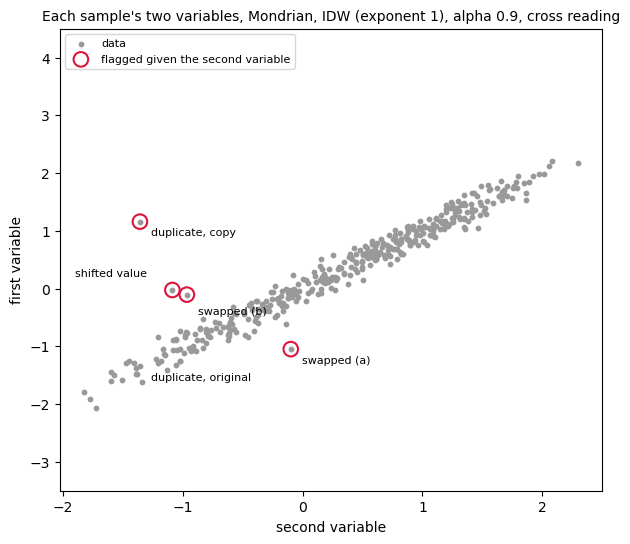

In [10]:
start = time.perf_counter()
cross = audit.cross(v)
print(f"cross reading in {time.perf_counter() - start:.1f} s")
compare = pd.DataFrame({"flagged by the values alone": [bool(audit.flags()[i]) for i in planted.values()],
                        "flagged given the second variable": [bool(cross.flag[i]) for i in planted.values()],
                        "gain given the second variable": [cross.gain[i] for i in planted.values()]},
                       index=list(planted))
display(compare.round(2))
others = [i for i in np.flatnonzero(cross.flag) if i not in planted.values()]
print(f"other data flagged given the second variable: {len(others)}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(v, values, s=10, c="0.6", label="data")
flagged = cross.flag.to_numpy()
ax.scatter(v[flagged], values[flagged], s=110, facecolors="none", edgecolors="crimson", lw=1.5,
           label="flagged given the second variable")
offsets = {"shifted value": (-70, 10), "swapped (b)": (8, -14)}
for name, i in planted.items():
    ax.annotate(name, (v[i], values[i]), xytext=offsets.get(name, (8, -10)), textcoords="offset points", fontsize=8)
ax.set_ylim(-3.5, 4.5)
ax.set_xlabel("second variable")
ax.set_ylabel("first variable")
ax.set_title(f"Each sample's two variables, {recipe}, cross reading", fontsize=10)
ax.legend(loc="upper left", fontsize=8)
plt.show()

Given the second variable, the shifted value and both swapped values stand out, where their
neighbours alone could not tell them apart. The copy of the duplicated sample is flagged, its
original not, the second variable siding with the original. The decimal error is flagged as before,
and lies below the frame of the figure. No other datum is flagged. The gain says how much the second
variable tells about each datum. It is large here, the two variables sharing most of what each sample
holds, while a second variable unrelated to the first would give a gain near 0 and no power.

### A list of actions

`recommend` gathers the readings into one list. It cleans the suspects first, replacing each flagged
datum by the median of its law and reading the original values against the laws computed again, until
the suspects no longer change, which clears data flagged only beside a suspect. The results of `cross`
and `null_flags` computed above enter the list as they are, without being computed again.

In [11]:
recommendations = audit.recommend(cross=cross, null=null)
recommendations["planted"] = [names.get(d, "") for d in recommendations.datum]
display(recommendations.head(8))
print("actions:", recommendations.attrs["counts"])
print("context:", recommendations.attrs["context"]["verdict"])
effect = recommendations.attrs["effect"]
print(f"measuring them again would change the cross-validated predictions of the other data by "
      f"{effect['mean_abs_change']:.3f} on average, by {effect['max_abs_change']:.2f} at most "
      f"(datum {effect['datum_most_changed']})")

,datum,value,action,reason,q_value,group,planted
0,3,-10.943707,measure again,surprising once its neighbours are cleaned; in...,1.654919e-14,None,decimal error
1,400,1.159402,measure again,inconsistent with the second variable measured...,1.927560e-08,None,"duplicate, copy"
2,83,-1.048010,measure again,inconsistent with the second variable measured...,9.307465e-06,None,swapped (a)
3,167,-0.104389,measure again,inconsistent with the second variable measured...,2.699865e-04,None,swapped (b)
4,43,-0.024012,measure again,inconsistent with the second variable measured...,1.373663e-02,None,shifted value
5,209,-1.340598,measure one of the pair again,"co-located with datum 400, the values 2.5 apart",2.659879e-03,None,"duplicate, original"
6,28,-0.056871,sample more nearby,"law resting on little evidence (support 1.00, ...",NaN,None,patch
7,30,-0.728167,sample more nearby,"law resting on little evidence (support 1.00, ...",NaN,None,


actions: {'sample more nearby': 22, 'measure again': 5, 'measure one of the pair again': 1}
context: beyond clean data
measuring them again would change the cross-validated predictions of the other data by 0.029 on average, by 2.70 at most (datum 34)


Every planted problem heads the list. The decimal error, the copy of the duplicated sample, the two
swapped values and the shifted value are to be measured again, the original of the duplicated sample
as one of a pair. The list never says to remove a datum. Measuring again confirms a true value and
corrects an error, so the patch, had one of its data been listed, would lose nothing. The places to
sample more are data whose laws say less than the distribution of all the data, a few of them inside
the patch, where sampling would delimit it. The replicates of `null_flags` put the strongest datum
beyond what clean data produce. Measuring the listed data again would leave most predictions as they
are, while it would move the one beside the decimal error by more than two units.

### Real data

The Andes data bundled with Spatialize hold copper grades of 400 samples on a plane. A search chooses
the ensemble, the audit reads its calibration first, then its flags, and `null_flags` tells how many
flags clean data would get there.

Mondrian, IDW (exponent 4), alpha 0.9


,alpha,observed,z
0,0.50,0.665,6.600
1,0.80,0.855,2.750
2,0.90,0.908,0.500
3,0.95,0.942,-0.688
4,0.99,0.978,-2.513


tails calibrated, centre too wide, information z 9.98, flags 3
{'q': 0.05, 'observed': 3, 'expected': 2.85, 'share_with_flags': 0.85, 'p_value': 0.619, 'p_value_strongest': 0.667}


,datum,value,action,reason,q_value,group
0,194,0.372,measure again,surprising once its neighbours are cleaned,0.001266,None
1,281,1.075,measure again,surprising once its neighbours are cleaned,0.001266,None
2,320,1.856,measure again,surprising once its neighbours are cleaned,0.012717,None
3,8,1.467,sample more nearby,"law resting on little evidence (support 1.00, ...",NaN,None
4,12,1.535,sample more nearby,"law resting on little evidence (support 1.00, ...",NaN,None
5,14,2.420,sample more nearby,"law resting on little evidence (support 1.00, ...",NaN,None


actions: {'sample more nearby': 43, 'measure again': 3} | context: an order of review


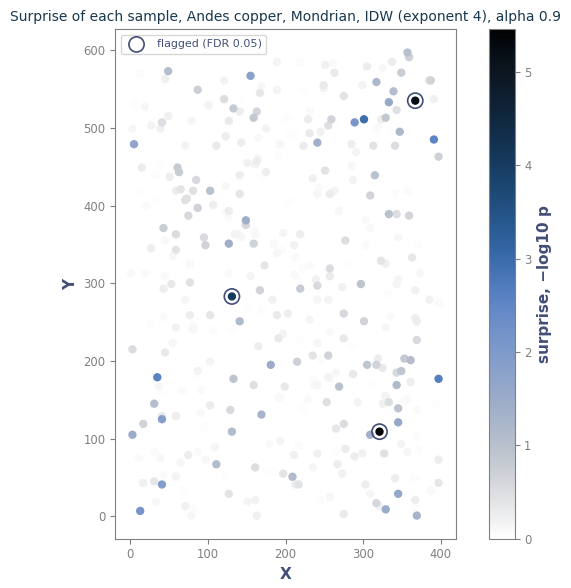

In [12]:
from spatialize.data import load_drill_holes_andes_2D

samples, locations, _, _ = load_drill_holes_andes_2D()
andes_points, andes_values = samples[["x", "y"]].values, samples["cu"].values
andes_search = esi_hparams_search(andes_points, andes_values, locations[["x", "y"]].values,
                                  local_interpolator="idw", griddata=False, k=10, exponent=[1.0, 2.0, 4.0],
                                  alpha=(0.7, 0.8, 0.9), n_partitions=[50], seed=1500, callback=quiet)
andes_best = andes_search.best_result()
andes_recipe = f"Mondrian, IDW (exponent {andes_best['exponent']:g}), alpha {andes_best['alpha']:g}"
andes = posterior_audit(andes_points, andes_values, local_interpolator="idw", n_partitions=300, seed=1500,
                        best_params_found=andes_best, callback=quiet)
c = andes.calibration(information=True)
print(andes_recipe)
display(c["coverage"][["alpha", "observed", "z"]].round(3))
print(f"tails {c['verdict']}, centre {c['centre']}, information z {c['information']['z']:.2f}, "
      f"flags {int(andes.flags().sum())}")
andes_null = andes.null_flags(n_replicates=20)
print({k: round(val, 3) for k, val in andes_null.attrs.items() if k != "data"})
andes_recommendations = andes.recommend(null=andes_null)
display(andes_recommendations.head(6))
print("actions:", andes_recommendations.attrs["counts"], "| context:", andes_recommendations.attrs["context"]["verdict"])
fig = andes.plot_map(figsize=(7, 6))
fig.axes[0].set_title(f"Surprise of each sample, Andes copper, {andes_recipe}", fontsize=10)
plt.show()

The tails of the laws are calibrated by their coverage, while their centre is too wide, two thirds of
the data falling inside the intervals of probability one half. The information check calls the laws
too narrow or off-centre. Its excess comes from a few samples far in the tails, their excess between
13 and 21 nats, while the median excess is negative, as a wide centre makes it. Three samples are
flagged, about what clean data would get here, and the most surprising of them is no stronger than
those of the replicates. The flags therefore give an order of review, the most surprising samples
first, not evidence of errors. The list of recommendations says so, naming the three samples to
measure again as an order of review, with 43 places where the laws rest on little evidence. The
provenance of those samples decides.

## Pitfalls

- **Flags read before the calibration.** Laws too narrow flag clean data by the dozen. Read
  `calibration(information=True)` first, and correct the laws or coarsen the partitions when the tails
  are too narrow.
- **The list taken as data to remove.** `recommend` lists data to measure again. A value measured again
  that comes back the same belongs to the field, however surprising.
- **A flag taken as a verdict.** A flagged value may be an error or a part of the domain the other data do
  not represent. Read the shift of its neighbours, then the provenance of the datum.
- **The false discovery rate taken as a promise.** The flags keep it only approximately. `null_flags`
  measures the false flags on the data at hand.
- **Entropies compared across variables or scales.** An entropy depends on the units. Compare the
  information gain, which does not.
- **A second variable predicted, not measured.** `cross` needs both variables on the same samples,
  since what they share at the scale of the sample is lost when one is predicted from its neighbours.
- **Isolated data under `empty_cells="nan"`.** Their laws rest on the few partitions whose cells hold
  other data, the share `support` reports. `"coarsen"` or `"mark"` gives every datum a law in every
  partition.

## Try it yourself

1. Plant a decimal error in a datum of the cluster and read its shift and its flag.
2. Replace the second variable by an unrelated one, `np.random.default_rng(0).normal(size=len(values))`,
   and read the gain and the flags of `cross`.
3. Audit the Andes data with `tails="gpd"` and compare the calibration and the flags.

## Next

- *Uncertainty at a location*, for the widened laws the audit reads.
- *Evaluating an interpolator*, for cross-validation and its scores.
- *Spatial entropy, mutual information*, for the information two variables share across a region.
- The documentation's [Posterior analysis of the data](https://spatialize.readthedocs.io/en/latest/theory/posterior.html)
  (theory) and [Posterior analysis](https://spatialize.readthedocs.io/en/latest/reference/spa.html)
  (reference).